# SecondLook | 07 Letter audit: faithfulness and tone

**Goal:** an independent check that every claim in a drafted letter matches the model's real reasons, plus a tone score, before a loan officer sends it.

**Why the Step 6 rule checks aren't enough:** they verify *which* factors a letter cites, that amounts come from the fact sheet, and that no sensitive words appear. They can't read meaning. In Phase 1 a letter passed every rule while calling a car the applicant already owns "the car you plan to buy".

**How the audit works** (`src/secondlook/letter_audit.py`):
1. **Blind review (Claude Haiku 5.5).** Claude reads **only the letter**, never the fact sheet, and lists every factual claim: the words, what it is about, the value it quotes, and whether the letter presents it as a concern or a strength. It also rates the tone (respectful, clear, empathetic, 1 to 5). Keeping it blind means it can't "see" what the letter was supposed to say and excuse it.
2. **Matching (Claude Haiku 5.5).** A second call links each claim to a fact-sheet entry and writes a one-line note, then says whether the wording is fair.
3. **Verdict (Python, deterministic).** A claim is *supported* only if it matches a reason the model really gave, in the right direction (raised vs lowered risk), with numbers that agree, and is fairly worded. Offers must quote the path to approval's exact terms.
4. **Tone three ways:** VADER and TextBlob (word-list sentiment from the NLP module, run locally) and the Claude rubric from step 1.

**faithfulness = supported claims ÷ checkable claims.** General statements ("a loan officer will review it", "on-time payments show a reliable record") are allowed by the letter prompt and not counted.

## 1. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR
from secondlook.letter_audit import audit_letter, judge_claims, summarise, lexicon_tone, AUDIT_VERSION
from secondlook.letters import MODEL

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 2. The letters being audited

The 30 demo letters in the app: 10 approve, 10 under review and 10 decline, drafted with prompt **v7**. Version 7 exists because of this audit (Section 4).

In [2]:
letters = json.loads((ROOT / "app" / "demo_data" / "letters.json").read_text(encoding="utf-8"))
print(f"{len(letters)} letters, prompt {sorted({l['prompt_version'] for l in letters.values()})}, model {MODEL}")
print(pd.Series([l["decision"] for l in letters.values()]).value_counts().to_string())
print(f"With adjusted terms (a path to approval): {sum(bool(l['fact_sheet'].get('adjusted_terms')) for l in letters.values())}")
print(f"Passed the rule checks when drafted: {sum(l['checks_passed'] for l in letters.values())}")

30 letters, prompt ['v7'], model claude-haiku-5-5
approve         10
under_review    10
decline         10
With adjusted terms (a path to approval): 12
Passed the rule checks when drafted: 30


## 3. Audit all 30 letters

Two Claude calls per letter, cached on disk, so re-running the notebook costs nothing.

In [3]:
audits = {k: audit_letter(l) for k, l in letters.items()}     # cached after the first run
rows = []
for k, a in audits.items():
    l = letters[k]
    rows.append({"applicant": l["applicant_id"], "decision": l["decision"], "claims checked": a["n_claims"],
                 "supported": a["n_supported"], "faithfulness": a["faithfulness"], "passed": a["passed"],
                 "top-3 reasons covered": a["coverage_top3"], "respectful": a["tone"]["respectful"],
                 "clear": a["tone"]["clear"], "empathetic": a["tone"]["empathetic"],
                 "vader": a["tone"]["vader_compound"], "textblob": a["tone"]["textblob_polarity"],
                 "subjectivity": a["tone"]["textblob_subjectivity"], "audit cost ($)": a["cost_usd"]})
res = pd.DataFrame(rows)
print(f"Claims checked: {res['claims checked'].sum()}   supported: {res['supported'].sum()} "
      f"({res['supported'].sum() / res['claims checked'].sum():.1%})")
print(f"Letters with every claim supported and no issue: {res['passed'].sum()} of {len(res)}")
print(f"Mean faithfulness by decision:")
print(res.groupby("decision")["faithfulness"].agg(["mean", "min", "count"]).round(3).to_string())
cov = res["top-3 reasons covered"].dropna()
print(f"\nTop-3 risk reasons mentioned (under review and decline letters): mean {cov.mean():.0%}, min {cov.min():.0%}")
print(f"Audit cost: total ${res['audit cost ($)'].sum():.4f}, mean ${res['audit cost ($)'].mean():.5f} per letter")

Claims checked: 178   supported: 163 (91.6%)
Letters with every claim supported and no issue: 16 of 30
Mean faithfulness by decision:
               mean    min  count
decision                         
approve       0.893  0.667     10
decline       0.906  0.667     10
under_review  0.932  0.750     10

Top-3 risk reasons mentioned (under review and decline letters): mean 70%, min 33%
Audit cost: total $0.0276, mean $0.00092 per letter


## 4. What the audit flagged

Every claim that was not supported, with the audit's reason.

**How this audit already improved the letters:** the first audit run (on the v6 letters) flagged **five decline letters that offered "a loan on different terms"** even though the model had found no path to approval. They were offering the applicant's original loan back as a possibility, which would mislead someone who had just been declined. The rule checks passed them because every amount was in the fact sheet. We changed the letter prompt (v7) and added a rule check for it. In the run below, no letter offers terms without a path.

In [4]:
flagged = [(letters[k]["applicant_id"], letters[k]["decision"], i) for k, a in audits.items() for i in a["issues"]]
if flagged:
    for sid, dec, issue in flagged:
        print(f"#{sid} ({dec}): {issue}\n")
else:
    print("No issues flagged.")

#348947 (approve): "Your regular repayment amount of 13,500 also shows that the payment plan fits the loan we are offering, which lenders consider when reviewing a loan.": misdescribes Regular repayment amount: The claim says the 13,500 repayment amount fits the loan offered, adding a general reason lenders review this, but the fact sheet does not state that the plan fits the loan as a comparison.

#220042 (approve): "We also considered the regular repayment amount of 5,404 and the loan amount of 74,182, which were part of the overall picture that led to this approval.": not one of the reasons the model gave

#131441 (approve): "Your regular repayment amount of 13,869 is a clear, fixed figure you can plan around each period": misdescribes Regular repayment amount: The letter calls the repayment amount fixed and easy to plan around, which adds a claim about fixed terms that the fact sheet does not state.

#230043 (approve): tone: respect scored 3/5 (The letter opens warmly but then list

Most remaining flags are about **embellishment**: the letter adds an interpretation the facts don't state ("which shows you have managed longer repayment plans", "fits within our lending guidelines"). These are exactly the meaning-level problems rules can't catch. But not every flag is a real problem, so we read each one.

## 5. Is the audit right? We checked every flag by hand

An automated judge is only useful if its flags mean something. We read all of them and labelled each as a **real problem** or a **false alarm**. These are our own judgements; a second reviewer should check them.

In [5]:
# Our own reading of every flag above (applicant, words from the flagged claim, label, why)
LABELS = [
    (348947, "fits the loan we are offering", "real", "invents a claim that the payment fits the loan"),
    (220042, "part of the overall picture", "false alarm", "accurate but vague; one claim covering two entries"),
    (131441, "fixed figure you can plan around", "real", "adds that the payment is fixed, which the facts don't say"),
    (230043, "respect scored", "real", "cites '75% of past applications cancelled' as a strength: confusing for the applicant"),
    (416405, "lending guidelines", "real", "invents a lending-guideline comparison"),
    (370614, "strong across the reports", "false alarm", "average, highest and lowest scores are all listed strengths"),
    (209138, "sustained period", "real", "overstates what an average of about 10 payments shows"),
    (210293, "record of approvals", "real", "adds a conclusion the ratio doesn't support"),
    (248335, "adds to the overall risk", "false alarm", "the term is one of the risk factors, so this is fair"),
    (140627, "longer repayment plans", "real", "invented comparison: 'longer' than what?"),
    (140627, "close to the level we can approve", "false alarm", "a general statement, wrongly treated as a factor"),
    (402566, "limited repayment history", "real", "invents a cause: a low score is not missing history"),
    (402085, "based mainly on credit scores", "false alarm", "all four risk factors are external scores, so 'mainly' is fair"),
    (402085, "two individual scores", "false alarm", "'two' is a count, not a score value; one claim covering several factors"),
    (102778, "shorter repayment periods", "real", "invented comparison: 'shorter' than what?"),
    (339086, "the highest is 0.38", "false alarm", "accurate; one claim covering three factors cannot match a single code"),
]
lab = pd.DataFrame(LABELS, columns=["applicant", "words", "label", "why"])
matched = []
for sid, dec, issue in flagged:
    hit = lab[(lab["applicant"] == sid) & lab["words"].map(lambda w: w in issue)]
    assert len(hit) == 1, f"flag without exactly one label: #{sid} {issue[:80]}"
    matched.append(hit.index[0])
assert sorted(matched) == list(lab.index), "a label matches no flag"
counts = lab["label"].value_counts()
print(f"Flags: {len(lab)}   real problems: {counts.get('real', 0)}   false alarms: {counts.get('false alarm', 0)}"
      f"   -> {counts.get('real', 0) / len(lab):.0%} of flags are real")
lab

Flags: 16   real problems: 9   false alarms: 7   -> 56% of flags are real


,applicant,words,label,why
0,348947,fits the loan we are offering,real,invents a claim that the payment fits the loan
1,220042,part of the overall picture,false alarm,accurate but vague; one claim covering two entries
2,131441,fixed figure you can plan around,real,"adds that the payment is fixed, which the facts don't say"
3,230043,respect scored,real,cites '75% of past applications cancelled' as a strength: confusing for the applicant
4,416405,lending guidelines,real,invents a lending-guideline comparison
5,370614,strong across the reports,false alarm,"average, highest and lowest scores are all listed strengths"
6,209138,sustained period,real,overstates what an average of about 10 payments shows
7,210293,record of approvals,real,adds a conclusion the ratio doesn't support
8,248335,adds to the overall risk,false alarm,"the term is one of the risk factors, so this is fair"
9,140627,longer repayment plans,real,invented comparison: 'longer' than what?


## 6. Does the audit give the same answer twice?

Claude's answers vary slightly from call to call. We ran the full audit a second time on the same 30 letters, independently (its own cache), and compared.

In [6]:
# A second, independent audit of the same 30 letters (its own cache file, so it is billed once)
run2 = {k: audit_letter(l, cache_path=ROOT / "data" / "processed" / "audit_cache_run2.json") for k, l in letters.items()}
same_pass = np.mean([audits[k]["passed"] == run2[k]["passed"] for k in letters])
diff = np.mean([abs(audits[k]["faithfulness"] - run2[k]["faithfulness"]) for k in letters])
claims1 = sum(a["n_claims"] for a in audits.values()); claims2 = sum(a["n_claims"] for a in run2.values())
sup1 = sum(a["n_supported"] for a in audits.values()) / claims1; sup2 = sum(a["n_supported"] for a in run2.values()) / claims2
print(f"Letters with the same pass/fail verdict in both runs: {same_pass:.0%}")
print(f"Mean absolute difference in a letter's faithfulness: {diff:.3f}")
print(f"Claims checked: {claims1} vs {claims2};  supported: {sup1:.1%} vs {sup2:.1%}")
print(f"Letters passed: {sum(a['passed'] for a in audits.values())} vs {sum(a['passed'] for a in run2.values())}")
r1 = res.set_index("applicant")[["respectful", "clear", "empathetic"]]
r2 = pd.DataFrame({letters[k]["applicant_id"]: {m: run2[k]["tone"][m] for m in ["respectful", "clear", "empathetic"]} for k in letters}).T
print("Tone scores identical in both runs:", {m: f"{(r1[m] == r2.loc[r1.index, m]).mean():.0%}" for m in r1.columns})

Letters with the same pass/fail verdict in both runs: 73%
Mean absolute difference in a letter's faithfulness: 0.060
Claims checked: 178 vs 170;  supported: 91.6% vs 93.5%
Letters passed: 16 vs 20
Tone scores identical in both runs: {'respectful': '87%', 'clear': '63%', 'empathetic': '77%'}


**Interpretation:**
- **The overall picture is stable:** 91.6% vs 93.5% of claims supported, from 178 vs 170 claims.
- **Individual verdicts are not.** Only 73% of letters get the same pass/fail verdict in both runs (16 vs 20 passed), and the "clear" tone score matches in only 63% of letters. Borderline claims, like a mild embellishment, flip from run to run.
- **What this means for the product:** the audit is a **triage signal** for the loan officer ("look at these sentences"), not an automatic verdict. A letter is never sent on the audit's say-so, and a flag is a prompt to read, not a block.

## 7. Can it catch problems we plant on purpose?

The real letters contain few serious errors, so we also test the audit on **four deliberately broken copies** of one real letter (applicant 135305), each with one kind of mistake. The same five letters are saved in `tests/fixtures/audit_cases.json`, so `pytest` re-checks these verdicts offline on every run.

In [7]:
cases = json.loads((ROOT / "tests" / "fixtures" / "audit_cases.json").read_text(encoding="utf-8"))
changes = {"original": "none (the real letter for applicant 135305)",
           "invented_detail": "'Your car is about 4 years old' -> 'The car you plan to buy is about 4 years old'",
           "wrong_direction": "0% late payments described as a concern that counts against them",
           "wrong_amount": "offer of 508,842 changed to 500,000",
           "rude": "'Thank you for applying' -> 'Frankly, applications like yours waste our time...'"}
adv = []
for name, c in cases.items():
    judged = judge_claims(c["raw"]["review"]["claims"], c["raw"]["matches"], c["letter"]["fact_sheet"])
    a = summarise(judged, c["letter"]["fact_sheet"], c["raw"]["review"], lexicon_tone(c["letter"]["body"]))
    adv.append({"case": name, "change": changes[name], "caught": not a["passed"], "faithfulness": round(a["faithfulness"], 2),
                "respect (Claude)": a["tone"]["respectful"], "VADER": round(a["tone"]["vader_compound"], 2),
                "issue found": a["issues"][0][:150] if a["issues"] else ""})
adv = pd.DataFrame(adv)
adv

,case,change,caught,faithfulness,respect (Claude),VADER,issue found
0,original,none (the real letter for applicant 135305),False,1.00,4,0.95,
1,invented_detail,'Your car is about 4 years old' -> 'The car you plan to buy is about 4 years old',True,0.88,5,0.95,"""The car you plan to buy is about 4 years old"": misdescribes Age of the car the applicant already owns: The claim sa..."
2,wrong_direction,0% late payments described as a concern that counts against them,True,0.89,4,0.93,"""we are concerned that you have no record of late payments in the last year, which counts against your application"":..."
3,wrong_amount,"offer of 508,842 changed to 500,000",True,0.89,4,0.95,"""a loan of 500,000"": quotes a loan amount, payment or term that is not in the fact sheet"
4,rude,"'Thank you for applying' -> 'Frankly, applications like yours waste our time...'",True,1.00,1,0.94,"tone: respect scored 1/5 (The letter opens by insulting the applicant ('applications like yours waste our time, and ..."


**Interpretation:**
- **All four broken letters are caught, and the original passes.** Each is caught by the right part of the audit: the misdescribed car by the matching step, the reversed strength by the direction check, the wrong amount by the number check, and the insult by the Claude tone rubric.
- **VADER rates the insulting letter 0.94**, about as positive as the polite original (0.95). Word-list sentiment counts friendly words like "thank", "pleased" and "possible", and can't see that one sentence insults the reader. This is why the rubric uses Claude for tone.

## 8. Three ways to score tone

Each letter is scored by VADER (compound, −1 to 1), TextBlob (polarity, −1 to 1, plus subjectivity, 0 to 1) and the Claude rubric (1 to 5).

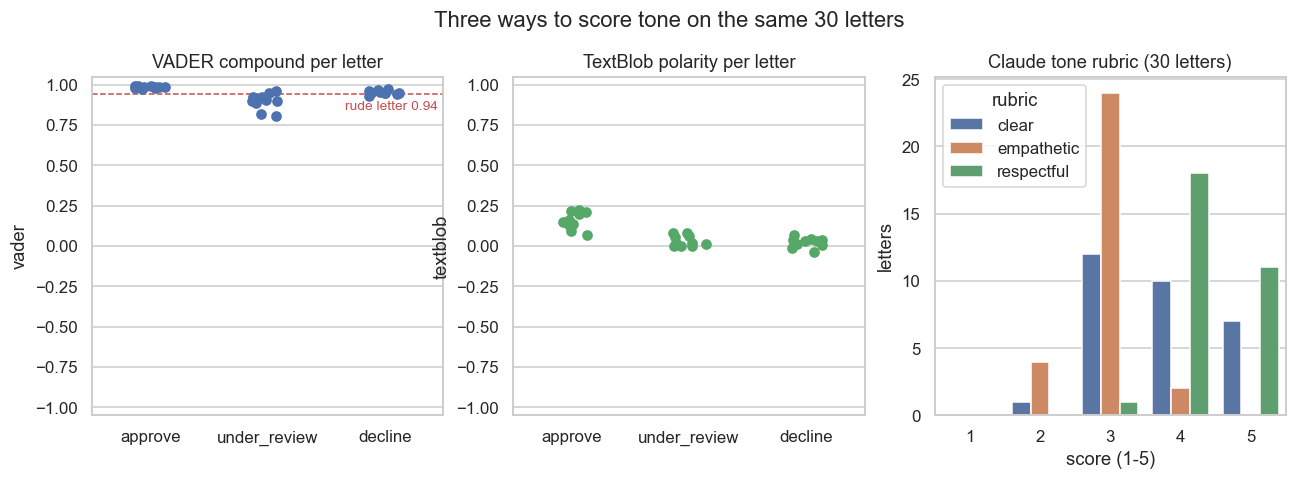

Claude rubric scores (letters per score):
score       2   3   4   5
rubric                   
clear       1  12  10   7
empathetic  4  24   2   0
respectful  0   1  18  11
VADER range: 0.80 to 0.99;  TextBlob range: -0.04 to 0.23

Spearman correlation between the methods:
              respectful  clear  empathetic  vader  textblob  subjectivity
respectful          1.00   0.81        0.49   0.56      0.68          0.24
clear               0.81   1.00        0.46   0.56      0.62          0.38
empathetic          0.49   0.46        1.00   0.19      0.25         -0.01
vader               0.56   0.56        0.19   1.00      0.56          0.47
textblob            0.68   0.62        0.25   0.56      1.00          0.41
subjectivity        0.24   0.38       -0.01   0.47      0.41          1.00

Mean by decision:
              respectful  clear  empathetic  vader  textblob  subjectivity
decision                                                                  
approve              4.8    4.5  

In [8]:
cols = ["respectful", "clear", "empathetic", "vader", "textblob", "subjectivity"]
corr = res[cols].corr(method="spearman")
rude_vader = adv.loc[adv["case"] == "rude", "VADER"].iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.stripplot(data=res, x="decision", y="vader", order=["approve", "under_review", "decline"], ax=axes[0], size=7, jitter=0.15)
axes[0].axhline(rude_vader, color="C3", ls="--", lw=1)
axes[0].text(2.45, rude_vader - 0.04, f"rude letter {rude_vader:.2f}", color="C3", ha="right", va="top", fontsize=9)
axes[0].set_ylim(-1.05, 1.05); axes[0].set_title("VADER compound per letter"); axes[0].set_xlabel("")
sns.stripplot(data=res, x="decision", y="textblob", order=["approve", "under_review", "decline"], ax=axes[1], size=7, jitter=0.15, color="C2")
axes[1].set_ylim(-1.05, 1.05); axes[1].set_title("TextBlob polarity per letter"); axes[1].set_xlabel("")
long = res.melt(id_vars="decision", value_vars=["respectful", "clear", "empathetic"], var_name="rubric", value_name="score")
sns.countplot(data=long, x="score", hue="rubric", order=[1, 2, 3, 4, 5], ax=axes[2])
axes[2].set_title("Claude tone rubric (30 letters)"); axes[2].set_xlabel("score (1-5)"); axes[2].set_ylabel("letters")
fig.suptitle("Three ways to score tone on the same 30 letters", y=1.03)
save(fig, "27_letter_tone"); plt.show()

print("Claude rubric scores (letters per score):")
print(long.groupby("rubric")["score"].value_counts().unstack(fill_value=0).to_string())
print(f"VADER range: {res['vader'].min():.2f} to {res['vader'].max():.2f};  TextBlob range: {res['textblob'].min():.2f} to {res['textblob'].max():.2f}\n")
print("Spearman correlation between the methods:")
print(corr.round(2).to_string())
print("\nMean by decision:")
print(res.groupby("decision")[cols].mean().round(2).to_string())

**Interpretation:**
- **VADER says every letter is very positive** (0.80 to 0.99), declines included. Formal, polite wording ("thank you", "happy to help") swamps the bad news, so VADER can't tell a kind decline from a cheerful approval, and it missed the insult in Section 7.
- **TextBlob is nearly flat** (−0.04 to 0.23). It is a little higher for approvals, but close to zero for both under-review and decline letters.
- **The Claude rubric spreads the letters out and finds a weakness.** Respect is high (29 of 30 letters score 4 or 5), but **empathy scores only 2 or 3 in 28 of 30 letters**. The letters are polite but rarely acknowledge the applicant's situation. That is a concrete thing to improve in the letter prompt.
- **The methods partly agree on respect** (Spearman 0.56 with VADER, 0.68 with TextBlob), but **barely on empathy** (0.19 and 0.25). Word lists measure friendly vocabulary, not whether a letter acknowledges the reader.

## 9. Limitations

- **The judge is also an LLM.** It makes mistakes (7 of 16 flags were false alarms) and varies between runs (73% pass/fail agreement). It supports a loan officer's review; it doesn't replace it.
- **One claim, one factor.** A sentence covering several factors at once ("the average is 0.23, the lowest 0.07 and the highest 0.38") can only be linked to one code, which produced two of the false alarms.
- **Recall is tested on four planted errors, not measured on a large labelled set.** A proper estimate would need many letters labelled by people.
- **The tone rubric is Claude's opinion.** It is useful for ranking and spotting outliers, but it isn't a measured customer reaction.
- **Cost:** about $0.0009 per letter for the two audit calls, on top of about $0.0007 to draft the letter.

## 10. Key findings

1. **The audit found a real bug the rule checks missed:** five decline letters offered other terms when no path to approval existed. Prompt v7 and a new rule fixed it.
2. **91.6% of claims in the 30 demo letters are supported**, and 16 of 30 letters have no flag at all. Most flags are embellishments, such as an invented comparison or an overstated conclusion.
3. **It catches all four planted errors** (invented detail, reversed direction, wrong amount, rude tone) while the original passes.
4. **9 of its 16 flags (56%) are real problems, and verdicts change between runs** (73% agreement). It is a triage tool for the officer, not a final verdict.
5. **Claude's rubric is the only one of the three tone methods that saw the rude letter**, and it found that the letters are respectful but low on empathy (2 or 3 out of 5 in 28 of 30 letters).
6. Cost: about **$0.0009 per letter**. The app shows the audit next to every letter, including ones drafted live.